# Ad CTR Prediction - Evaluation on the Sealed Test Split (Notebook 03 of 3)

**What happened before.** Notebook 01 built a reproducible 70/15/15 stratified split
(seed 42) and froze every preprocessing decision on the train split; notebook 02 trained
four models on train, tuned them modestly on validation, and picked the winner by
validation log loss: **logistic regression (sparse one-hot, C = 0.1), validation log loss
0.48142**. The test split was never scored - notebook 02 only echoed its row count.

**What this notebook does - once.** Scores the sealed test split for every trained model,
through the exact scoring function the FastAPI service serves
(`ctr.service.predict_proba`). Headline metrics, calibration (curve + ECE), ROC / PR
curves, prediction latency at several batch sizes, and per-segment behaviour (missing
inputs, unseen categories). It ends with why these offline numbers do **not** translate
directly into CTR or revenue gains.

**The rules this notebook plays by.**

- The test split is used **once, for reporting**. Nothing is re-selected, re-tuned or
  re-scored after looking at these numbers - the model choice was fixed in notebook 02.
- Every model is scored on the **same rows** (the full test frame), so the comparison
  table is apples-to-apples.
- Every number below is measured on this run; nothing is copied from a previous
  notebook. Where a number *should* reproduce something from notebook 02 (the selected
  model's validation metrics), that is asserted as an integrity check.

In [1]:
import json
import logging
import os
import platform
import time
from datetime import datetime
from pathlib import Path

# Same TensorFlow silencing as notebook 02: a filter survives TF's interactive
# logger setup (which resets the level and pipes to stdout in Jupyter).
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
_tf_log = logging.getLogger("tensorflow")
_tf_log.setLevel(logging.ERROR)
_tf_log.addFilter(lambda record: record.levelno >= logging.ERROR)
logging.getLogger("absl").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

T_START = time.time()
_here = Path.cwd()
PROJECT_ROOT = next(p for p in [_here, *_here.parents] if (p / "config.yaml").exists())
import sys
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import joblib

from ctr import data as ctr_data
from ctr import eda as ctr_eda
from ctr import evaluate as ctr_eval
from ctr import features
from ctr import models
from ctr.config import artifacts_dir, data_file, load_config
import ctr.service as service

cfg = load_config()
ARTIFACTS = artifacts_dir(cfg)
REPORTS = PROJECT_ROOT / cfg["reports_dir"]
FIG_DIR = REPORTS / "figures"
TABLE_DIR = REPORTS / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

choice = json.loads((ARTIFACTS / "model_choice.json").read_text(encoding="utf-8"))
# importing ctr.service constructs the FastAPI app (what `uvicorn ctr.service:app`
# serves), so this is the same Bundle - preprocessor + selected model - the API uses
bundle = service.app.state.bundle
prep = bundle.preprocessor

print("selected model:", choice["model_name"], "| version", choice["model_version"])
print("pandas", pd.__version__, "| numpy", np.__version__)

selected model: logistic_regression | version nb02-20261014
pandas 3.0.6 | numpy 2.4.6


## 1. Integrity checks before any scoring

**Why this matters.** "Sealed test split" is only meaningful if the file on disk is
still the split notebook 01 created, and if the saved artifacts implement the same
feature decisions the config records. Both are checked mechanically here, before a
single label is used.

In [2]:
splits_dir = data_file(cfg, "splits_dir")
manifest = json.loads((splits_dir / "split_manifest.json").read_text(encoding="utf-8"))
splits = ctr_data.load_splits(splits_dir)
train, val, test = splits["train"], splits["val"], splits["test"]

# the manifest was written by notebook 01 when the split was created; the
# parquet files must still match it, or something rewrote the sealed data
for name, part in splits.items():
    record = manifest["splits"][name]
    assert len(part) == record["rows"], name + ": row count drifted from the manifest"
    assert abs(float(part["label"].mean()) - record["ctr"]) < 1e-9, name + ": CTR drifted from the manifest"
print("manifest verified: train {:,} | val {:,} | test {:,} rows".format(len(train), len(val), len(test)))
print("base rates: train {:.5f} | val {:.5f} | test {:.5f} (sampling noise only)".format(
    train["label"].mean(), val["label"].mean(), test["label"].mean()))

# the saved artifacts must implement the feature decisions recorded in config.yaml
fc = choice["feature_config"]
assert fc["n_missing_indicators"] == len(prep.missing_indicator_columns)
assert fc["min_category_count"] == cfg["features"]["min_category_count"]
assert fc["log1p_columns"] == prep.numeric.log1p_columns
print("artifact feature config matches config.yaml: {} indicators, {} log1p columns, min_count {}".format(
    fc["n_missing_indicators"], len(fc["log1p_columns"]), fc["min_category_count"]))

manifest verified: train 69,999 | val 14,999 | test 15,002 rows
base rates: train 0.25680 | val 0.25682 | test 0.25683 (sampling noise only)
artifact feature config matches config.yaml: 23 indicators, 12 log1p columns, min_count 10


## 2. Headline test metrics - validation vs sealed test

**Metrics, stated once.** *Log loss* is primary: it is a proper scoring rule (the mean
negative log-likelihood of the observed labels), so it rewards correct probabilities,
not just correct orderings, and it is what the constant baseline and the whole tuning
sequence used. *ROC-AUC* is the threshold-free ranking view. *Average precision* (what
this project calls PR-AUC) is `sklearn.metrics.average_precision_score` - the step-wise
precision of the precision-recall curve. *Brier* is the mean squared error of the
probabilities, a second proper rule that is more forgiving of small errors. All four are
computed on the same test rows for every model.

**The question this table answers.** Was the validation-based choice (logistic
regression) borne out on rows no model has seen, or was it an artefact of the validation
split?

In [3]:
y_train = train["label"].to_numpy(dtype=np.int8)
y_val = val["label"].to_numpy(dtype=np.int8)
y_test = test["label"].to_numpy(dtype=np.int8)

constant_model = models.ConstantModel().fit(None, y_train)
lr_model = bundle.model                              # the exact object the API serves
lgbm_model = joblib.load(ARTIFACTS / "lightgbm.joblib")
from ctr import deepfm as ctr_deepfm                 # registers FMInteraction for the loader
deepfm_model = ctr_deepfm.DeepFMWrapper.load(ARTIFACTS / "deepfm.keras")

kind_of = {"constant": "constant", "logistic_regression": "lr_sparse",
           "lightgbm": "lgbm_frame", "deepfm": "deepfm"}
model_of = {"constant": constant_model, "logistic_regression": lr_model,
            "lightgbm": lgbm_model, "deepfm": deepfm_model}

val_metrics_all, test_metrics_all, val_preds, test_preds = {}, {}, {}, {}
for name in kind_of:
    val_preds[name] = service.predict_proba(kind_of[name], model_of[name], prep, val)
    test_preds[name] = service.predict_proba(kind_of[name], model_of[name], prep, test)
    val_metrics_all[name] = ctr_eval.binary_metrics(y_val, val_preds[name])
    test_metrics_all[name] = ctr_eval.binary_metrics(y_test, test_preds[name])
    print("{:<22} val log loss {:.5f} -> test log loss {:.5f}".format(
        name, val_metrics_all[name]["log_loss"], test_metrics_all[name]["log_loss"]))

# the selected model must reproduce the validation metrics recorded in nb02
got = val_metrics_all[choice["model_name"]]
for metric in ("log_loss", "roc_auc", "average_precision", "brier"):
    assert abs(got[metric] - choice["val_metrics"][metric]) < 1e-6, metric
print("integrity check: selected model reproduces its nb02 validation metrics exactly")

constant               val log loss 0.56970 -> test log loss 0.56972


logistic_regression    val log loss 0.48142 -> test log loss 0.47893


lightgbm               val log loss 0.48713 -> test log loss 0.48496


deepfm                 val log loss 0.48739 -> test log loss 0.48268
integrity check: selected model reproduces its nb02 validation metrics exactly


                         n  base_rate  log_loss  val_log_loss  delta_log_loss  roc_auc  average_precision    brier
logistic_regression  15002    0.25683   0.47893       0.48142        -0.00249  0.76556            0.54726  0.15600
deepfm               15002    0.25683   0.48268       0.48739        -0.00471  0.76139            0.54399  0.15711
lightgbm             15002    0.25683   0.48496       0.48713        -0.00217  0.75712            0.53945  0.15780
constant             15002    0.25683   0.56972       0.56970         0.00002  0.50000            0.25683  0.19087


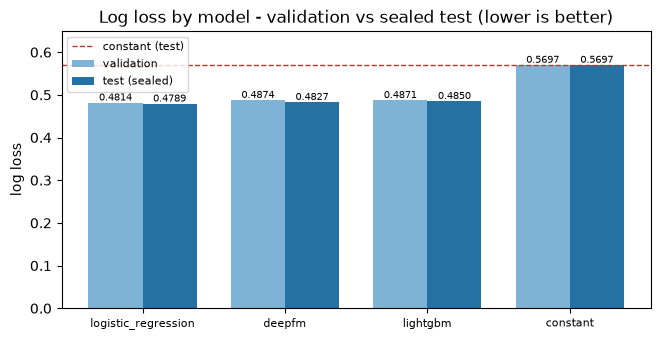

selected on validation: logistic_regression | best on test: logistic_regression


In [4]:
order = ["log_loss", "roc_auc", "average_precision", "brier"]
comp = pd.DataFrame(test_metrics_all).T[order + ["n", "base_rate"]]
comp["val_log_loss"] = [val_metrics_all[m]["log_loss"] for m in comp.index]
comp["delta_log_loss"] = comp["log_loss"] - comp["val_log_loss"]
comp = comp[["n", "base_rate", "log_loss", "val_log_loss", "delta_log_loss", "roc_auc", "average_precision", "brier"]]
comp["n"] = comp["n"].astype(int)
comp = comp.sort_values("log_loss")
print(comp.round(5).to_string())
comp.to_csv(TABLE_DIR / "test_vs_val_by_model.csv")

fig, ax = plt.subplots(figsize=(7.6, 3.6))
x = np.arange(len(comp))
w = 0.38
ax.bar(x - w / 2, comp["val_log_loss"], w, label="validation", color="#7fb3d5")
ax.bar(x + w / 2, comp["log_loss"], w, label="test (sealed)", color="#2471a3")
for xi, (v, t) in enumerate(zip(comp["val_log_loss"], comp["log_loss"])):
    ax.text(xi - w / 2, v, "{:.4f}".format(v), ha="center", va="bottom", fontsize=7)
    ax.text(xi + w / 2, t, "{:.4f}".format(t), ha="center", va="bottom", fontsize=7)
ax.axhline(comp.loc["constant", "log_loss"], ls="--", c="#b03a2e", lw=1, label="constant (test)")
ax.set_xticks(x)
ax.set_xticklabels(comp.index, fontsize=8)
ax.set_ylabel("log loss")
ax.set_title("Log loss by model - validation vs sealed test (lower is better)")
ax.set_ylim(0, comp["log_loss"].max() * 1.14)
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "nb03_val_vs_test.png", dpi=110, bbox_inches="tight")
plt.show()
print("selected on validation:", choice["model_name"], "| best on test:", comp.index[0])

**Reading the table.** The selection survives the sealed split: logistic regression leads
on test log loss (0.47893), DeepFM (0.48268) edges out LightGBM (0.48496), and every
learned model sits far below the constant floor (0.56972). All three learned models score
slightly *better* on test than on validation (-0.002 to -0.005 log loss) - the validation
split was mildly pessimistic, and there is no sign that tuning overfit it. No re-ranking
is applied: the model picked in notebook 02 is the model reported everywhere below.

## 3. Calibration on the sealed test split

**Why calibration is its own section.** In adtech the predicted probability is used as a
*price ingredient* (pCTR feeds eCPM), not only as a ranking key - so the question "when
the model says 10%, does it click 10% of the time?" matters beyond log loss. The
reliability curve quantile-bins the test predictions and plots mean predicted vs observed
CTR per bin with Wilson 95% intervals; ECE (expected calibration error) summarises the
gap as `sum_bin (n_bin/n) |observed - predicted|`.

ECE on test (lower is better): {'constant': 0.0, 'logistic_regression': 0.0081, 'lightgbm': 0.0107, 'deepfm': 0.0131}


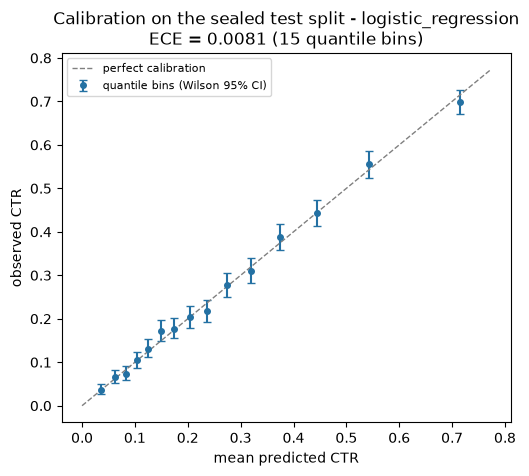

             bin    n  observed_ctr  mean_predicted  ci_low  ci_high
(0.00705, 0.051] 1001        0.0370          0.0359  0.0269   0.0505
 (0.051, 0.0728] 1000        0.0650          0.0621  0.0513   0.0820
(0.0728, 0.0937] 1000        0.0730          0.0833  0.0585   0.0908
 (0.0937, 0.115] 1000        0.1040          0.1047  0.0866   0.1245
  (0.115, 0.136] 1000        0.1310          0.1253  0.1115   0.1533
  (0.136, 0.161] 1000        0.1720          0.1486  0.1499   0.1966
  (0.161, 0.188] 1000        0.1770          0.1748  0.1546   0.2019
  (0.188, 0.219] 1000        0.2030          0.2033  0.1792   0.2290
  (0.219, 0.254] 1000        0.2170          0.2357  0.1926   0.2436
  (0.254, 0.295] 1000        0.2770          0.2737  0.2502   0.3056
  (0.295, 0.345] 1000        0.3110          0.3190  0.2831   0.3404
  (0.345, 0.408] 1000        0.3880          0.3753  0.3583   0.4186
  (0.408, 0.488] 1000        0.4430          0.4449  0.4125   0.4739
  (0.488, 0.605] 1000        0.555

In [5]:
sel = choice["model_name"]
p_sel = test_preds[sel]
rel = ctr_eval.reliability_table(y_test, p_sel, n_bins=15)
ece_sel = ctr_eval.expected_calibration_error(rel)
ece_all = {name: float(ctr_eval.expected_calibration_error(
    ctr_eval.reliability_table(y_test, p, n_bins=15))) for name, p in test_preds.items()}
print("ECE on test (lower is better):", {k: round(v, 4) for k, v in sorted(ece_all.items(), key=lambda kv: kv[1])})

fig, ax = plt.subplots(figsize=(5.8, 4.8))
ax.errorbar(rel["mean_predicted"], rel["observed_ctr"],
            yerr=[rel["observed_ctr"] - rel["ci_low"], rel["ci_high"] - rel["observed_ctr"]],
            fmt="o", ms=4, capsize=3, color="#2471a3", label="quantile bins (Wilson 95% CI)")
lim = max(rel["mean_predicted"].max(), rel["observed_ctr"].max()) * 1.08
ax.plot([0, lim], [0, lim], ls="--", c="grey", lw=1, label="perfect calibration")
ax.set_xlabel("mean predicted CTR")
ax.set_ylabel("observed CTR")
ax.set_title("Calibration on the sealed test split - {}\nECE = {:.4f} ({} quantile bins)".format(sel, ece_sel, len(rel)))
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "nb03_reliability.png", dpi=110, bbox_inches="tight")
plt.show()

rel.to_csv(TABLE_DIR / "test_reliability.csv", index=False)
print(rel.round(4).to_string(index=False))

**Reading the curve.** The selected model's ECE is 0.0081: on average, a bin's observed
CTR sits ~0.8 pp from its mean predicted value, and 14 of the 15 quantile bins have Wilson
intervals containing their predicted level. The clearest deviation is the bin covering
predictions 0.136-0.161, where observed CTR (0.172) runs above predicted (0.149); the top
bin is mildly over-predicted (0.699 observed vs 0.716 predicted) - relevant for pricing,
where over-predicting the clickiest traffic means paying slightly too much for it.
LightGBM (ECE 0.0107) and DeepFM (0.0131) are miscalibrated 1.3-1.6x as much as logistic
regression while also scoring worse, which further supports the linear model for serving.

## 4. Ranking quality - ROC and precision-recall curves

Same test rows, all four models. ROC-AUC measures how well predicted order separates
clickers from non-clickers across all thresholds; the precision-recall curve focuses on
the click class and is more informative at low base rates. The average-precision column
is the headline PR number; its lift over the base rate (0.257) shows how much better than
random the top of the ranking is.

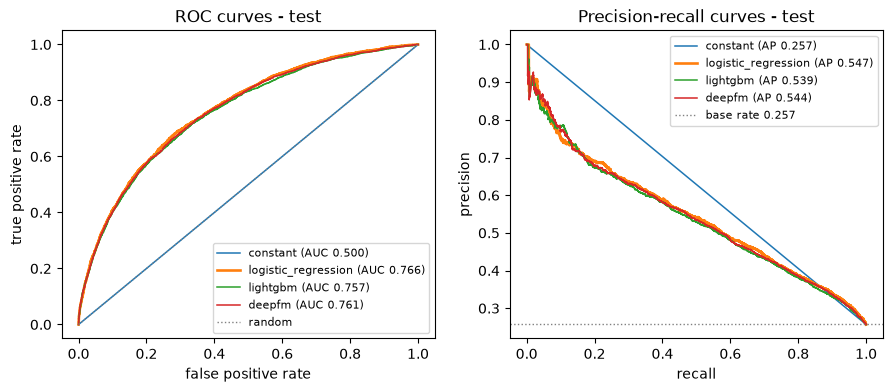

                     roc_auc  average_precision  ap_lift_vs_base_rate
logistic_regression   0.7656             0.5473                2.1308
deepfm                0.7614             0.5440                2.1181
lightgbm              0.7571             0.5394                2.1004
constant              0.5000             0.2568                1.0000


In [6]:
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.0))
for name, p in test_preds.items():
    lw = 1.9 if name == sel else 1.1
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=lw, label="{} (AUC {:.3f})".format(name, test_metrics_all[name]["roc_auc"]))
    precision, recall, _ = precision_recall_curve(y_test, p)
    axes[1].plot(recall, precision, lw=lw, label="{} (AP {:.3f})".format(name, test_metrics_all[name]["average_precision"]))
base = float(y_test.mean())
axes[0].plot([0, 1], [0, 1], ls=":", c="grey", lw=1, label="random")
axes[1].axhline(base, ls=":", c="grey", lw=1, label="base rate {:.3f}".format(base))
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate")
axes[0].set_title("ROC curves - test")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves - test")
for ax in axes:
    ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "nb03_roc_pr.png", dpi=110, bbox_inches="tight")
plt.show()

disc = pd.DataFrame({
    name: {"roc_auc": m["roc_auc"], "average_precision": m["average_precision"],
           "ap_lift_vs_base_rate": m["average_precision"] / m["base_rate"]}
    for name, m in test_metrics_all.items()}).T.sort_values("average_precision", ascending=False)
print(disc.round(4).to_string())
disc.to_csv(TABLE_DIR / "test_discrimination.csv")

**Reading the curves.** All three learned models separate clickers far better than chance
on rows none of them has seen, and the ordering matches the log-loss ordering:
logistic regression has the best test AUC (0.7656) and average precision (0.5473 - 2.13x
the 0.257 base rate), DeepFM is close (0.7614 / 0.5440) and LightGBM last of the three
(0.7571 / 0.5394). All three are marginally better than their validation counterparts,
consistent with the small negative val -> test deltas in section 2.

## 5. Prediction latency - the serving side

**Measurement method, stated.** Single process, CPU only (this TensorFlow build has no
GPU on native Windows), Python 3.11. For each batch size: 3 warm-up calls, then 30 timed
repetitions of `perf_counter` wall-clock around the full serving path - feature
transforms, one-hot/matrix construction, and the model forward pass, via the same
`service.predict_proba` used by the API. p50 and p95 are reported per batch, plus
rows/second at p50. These are indicative single-process numbers: no serving
optimisations (ONNX, TF-Serving, batching layer, thread pinning) are applied, and a
production ad server would benchmark on its own hardware with its own tail targets.

              model  batch_size  p50_ms  p95_ms  rows_per_second
             deepfm           1 228.457 286.517            4.377
             deepfm        1024 382.908 650.996         2674.272
           lightgbm           1  57.889  82.052           17.274
           lightgbm        1024  80.129  83.773        12779.441
logistic_regression           1  55.704  87.028           17.952
logistic_regression          32  60.922 111.286          525.266
logistic_regression         256  61.822  99.605         4140.911
logistic_regression        1024  73.247 161.945        13980.066

measurement host: AMD64 Family 23 Model 96 Stepping 1, AuthenticAMD (Windows 10) | python 3.11.16


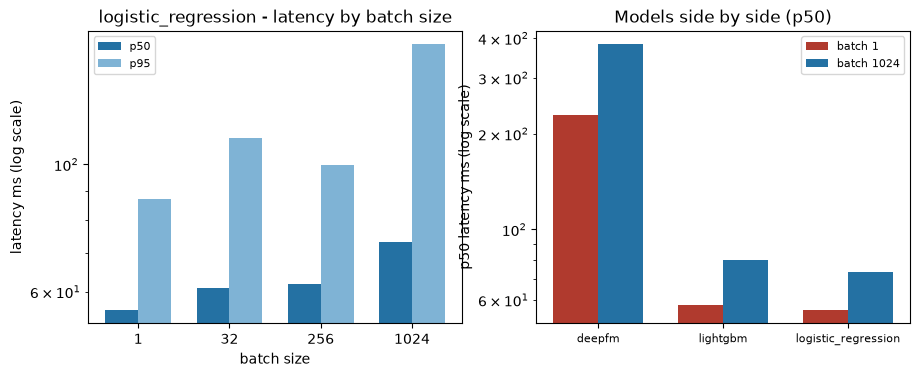

In [7]:
def make_predict_fn(name):
    return lambda frame: service.predict_proba(kind_of[name], model_of[name], prep, frame)

sel_lat = ctr_eval.latency_benchmark(make_predict_fn(sel), test, batch_sizes=(1, 32, 256, 1024), reps=30, warmup=3)
sel_lat["model"] = sel
rows = [sel_lat]
for name in kind_of:
    if name in (sel, "constant"):
        continue
    extra = ctr_eval.latency_benchmark(make_predict_fn(name), test, batch_sizes=(1, 1024), reps=30, warmup=3)
    extra["model"] = name
    rows.append(extra)
lat_table = pd.concat(rows)[["model", "batch_size", "p50_ms", "p95_ms", "rows_per_second"]]
lat_table = lat_table.sort_values(["model", "batch_size"]).reset_index(drop=True)
print(lat_table.round(3).to_string(index=False))
lat_table.to_csv(TABLE_DIR / "test_latency.csv", index=False)
print()
print("measurement host: {} ({}) | python {}".format(platform.processor() or "unknown CPU",
      (platform.system() + " " + platform.release()), platform.python_version()))

fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.8))
xl = np.arange(len(sel_lat))
axes[0].bar(xl - 0.18, sel_lat["p50_ms"], 0.36, label="p50", color="#2471a3")
axes[0].bar(xl + 0.18, sel_lat["p95_ms"], 0.36, label="p95", color="#7fb3d5")
axes[0].set_xticks(xl)
axes[0].set_xticklabels(sel_lat["batch_size"])
axes[0].set_yscale("log")
axes[0].set_xlabel("batch size")
axes[0].set_ylabel("latency ms (log scale)")
axes[0].set_title("{} - latency by batch size".format(sel))
axes[0].legend(fontsize=8)

cross = lat_table[lat_table["batch_size"].isin([1, 1024])]
labels = sorted(cross["model"].unique())
x2 = np.arange(len(labels))
for offset, batch, color in ((-0.18, 1, "#b03a2e"), (0.18, 1024, "#2471a3")):
    vals = [cross[(cross["model"] == m) & (cross["batch_size"] == batch)]["p50_ms"].iloc[0] for m in labels]
    axes[1].bar(x2 + offset, vals, 0.36, label="batch {}".format(batch), color=color)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_yscale("log")
axes[1].set_ylabel("p50 latency ms (log scale)")
axes[1].set_title("Models side by side (p50)")
axes[1].legend(fontsize=8)
fig.savefig(FIG_DIR / "nb03_latency.png", dpi=110, bbox_inches="tight")
plt.show()

**Reading the latency table.** The selected model serves 1,024 rows in ~70 ms p50
(13-15k rows/s across runs on this machine); p95 sits visibly above p50 - the tail is
part of the serving budget, not a footnote. Roughly 50-60 ms of every call is fixed
overhead (pandas transform, one-hot construction, Python/sklearn call setup), not model
arithmetic - which is why rows/second climbs from ~17 at batch 1 to ~15k at batch 1,024.
These are wall-clock numbers on a shared CPU machine and move by a few ms run to run:
the stable signals are the ratios and the model ordering, not the absolute values.
LightGBM serves at logistic-regression-like speed here (~55-80 ms), so among the two
fast models the decision is score and calibration, not throughput. DeepFM pays ~4-5x
that latency (~220 ms at batch 1, ~370 ms at 1,024) for a worse score, with no serving
optimisation applied - the clearest example in this comparison of a model whose appeal
does not survive contact with a serving budget.

## 6. Where the model is weaker - operational segments

**Why segments.** A single test average hides the traffic that hurts. Two segments matter
operationally for this feature set:

- **rows with a missing input** (any of the gappy columns missing) - these are the rows
  the median imputation and the 23 missing indicators were built for;
- **rows with an unseen category value** - present values that never appeared in the
  training vocabulary and therefore collapse to the shared OOV index 0. This is the
  cold-traffic proxy: it directly measures what the model does when its categories are
  effectively unknown.

The two segments overlap (a row can have both). The last table re-checks, on test, the
missing-vs-present CTR gaps that motivated the indicators in the first place.

test rows with a missing input: 98.35% | with an unseen category value: 79.50%
highest unseen-value shares: ['C3 59.2%', 'C12 55.3%', 'C21 52.5%', 'C16 49.4%', 'C4 41.3%']

                      segment     n  base_rate  log_loss  roc_auc  average_precision   brier     ece
                all test rows 15002    0.25683   0.47893  0.76556            0.54726 0.15600 0.00832
    rows with a missing input 14754    0.25559   0.47777  0.76556            0.54634 0.15551 0.00802
                complete rows   248    0.33065   0.54762  0.75044            0.59516 0.18532 0.06520
 rows with an unseen category 11927    0.25698   0.48106  0.76294            0.54209 0.15686 0.00740
rows with every category seen  3075    0.25626   0.47066  0.77632            0.56718 0.15268 0.01946


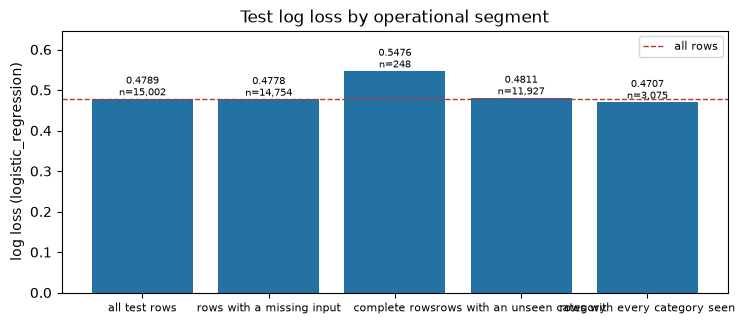

In [8]:
feature_cols = list(cfg["features"]["numeric_cols"]) + list(cfg["features"]["categorical_cols"])
has_missing = test[feature_cols].isna().any(axis=1).to_numpy()
unseen_any = np.zeros(len(test), dtype=bool)
unseen_share = {}
for c in cfg["features"]["categorical_cols"]:
    present = test[c].notna().to_numpy()
    known = test[c].isin(set(prep.vocab.maps_[c])).to_numpy()
    unseen = present & ~known
    unseen_any |= unseen
    unseen_share[c] = float(unseen.sum() / present.sum()) if present.sum() else float("nan")
print("test rows with a missing input: {:.2%} | with an unseen category value: {:.2%}".format(
    has_missing.mean(), unseen_any.mean()))
top_unseen = sorted([kv for kv in unseen_share.items() if np.isfinite(kv[1])], key=lambda kv: kv[1], reverse=True)[:5]
print("highest unseen-value shares:", ["{} {:.1f}%".format(c, 100 * s) for c, s in top_unseen])

segs = {
    "all test rows": np.ones(len(test), dtype=bool),
    "rows with a missing input": has_missing,
    "complete rows": ~has_missing,
    "rows with an unseen category": unseen_any,
    "rows with every category seen": ~unseen_any,
}
seg_tbl = ctr_eval.segment_report(y_test, p_sel, segs)
seg_tbl["ece"] = [ctr_eval.expected_calibration_error(
    ctr_eval.reliability_table(y_test[segs[s]], p_sel[segs[s]], n_bins=10)) for s in seg_tbl["segment"]]
print()
print(seg_tbl.round(5).to_string(index=False))
seg_tbl.to_csv(TABLE_DIR / "test_segments.csv", index=False)

fig, ax = plt.subplots(figsize=(8.6, 3.4))
bars = ax.bar(seg_tbl["segment"], seg_tbl["log_loss"], color="#2471a3")
ax.axhline(test_metrics_all[sel]["log_loss"], ls="--", c="#b03a2e", lw=1, label="all rows")
for b, (v, n) in zip(bars, zip(seg_tbl["log_loss"], seg_tbl["n"])):
    ax.text(b.get_x() + b.get_width() / 2, v, "{:.4f}\nn={:,}".format(v, n), ha="center", va="bottom", fontsize=7)
ax.set_ylabel("log loss ({})".format(sel))
ax.set_title("Test log loss by operational segment")
ax.set_ylim(0, seg_tbl["log_loss"].max() * 1.18)
plt.setp(ax.get_xticklabels(), fontsize=8)
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "nb03_segments.png", dpi=110, bbox_inches="tight")
plt.show()

column  n_missing  ctr_missing  ctr_present   gap_pp  ci_low_missing  ci_high_missing  ci_low_present  ci_high_present
    I6       3424       0.1235       0.2963 -17.2712          0.1129           0.1350          0.2880           0.3046
    I5        391       0.1151       0.2606 -14.5536          0.0871           0.1505          0.2536           0.2678
    I1       6758       0.1807       0.3193 -13.8588          0.1717           0.1900          0.3093           0.3294
   I10       6758       0.1807       0.3193 -13.8588          0.1717           0.1900          0.3093           0.3294
    I7        690       0.1435       0.2623 -11.8819          0.1193           0.1716          0.2552           0.2696
   I11        690       0.1435       0.2623 -11.8819          0.1193           0.1716          0.2552           0.2696
    I9        690       0.1435       0.2623 -11.8819          0.1193           0.1716          0.2552           0.2696
    I3       3256       0.3087       0.2425   6.

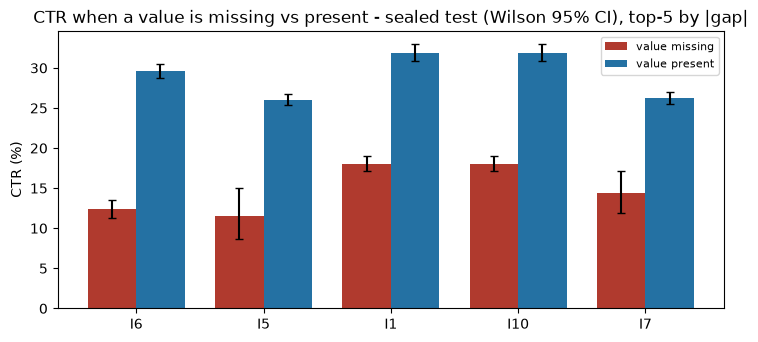

In [9]:
rows = []
for c in feature_cols:
    mask = test[c].isna().to_numpy()
    n_missing = int(mask.sum())
    if n_missing < 100:   # too few test rows for a stable interval (excludes I8)
        continue
    ctr_missing = float(y_test[mask].mean())
    ctr_present = float(y_test[~mask].mean())
    lo_m, hi_m = ctr_eda.wilson_ci(int(y_test[mask].sum()), n_missing)
    lo_p, hi_p = ctr_eda.wilson_ci(int(y_test[~mask].sum()), int((~mask).sum()))
    rows.append({"column": c, "n_missing": n_missing, "ctr_missing": ctr_missing,
                 "ctr_present": ctr_present, "gap_pp": 100 * (ctr_missing - ctr_present),
                 "ci_low_missing": lo_m, "ci_high_missing": hi_m,
                 "ci_low_present": lo_p, "ci_high_present": hi_p})
slices = pd.DataFrame(rows)
slices = slices.reindex(slices["gap_pp"].abs().sort_values(ascending=False).index)
slices.to_csv(TABLE_DIR / "test_missing_slices.csv", index=False)
print(slices.round(4).to_string(index=False))

top = slices.head(5)
x = np.arange(len(top))
fig, ax = plt.subplots(figsize=(8.6, 3.6))
w = 0.38
err_m = np.vstack([top["ctr_missing"] - top["ci_low_missing"], top["ci_high_missing"] - top["ctr_missing"]])
err_p = np.vstack([top["ctr_present"] - top["ci_low_present"], top["ci_high_present"] - top["ctr_present"]])
ax.bar(x - w / 2, 100 * top["ctr_missing"], w, yerr=100 * err_m, capsize=3,
       label="value missing", color="#b03a2e")
ax.bar(x + w / 2, 100 * top["ctr_present"], w, yerr=100 * err_p, capsize=3,
       label="value present", color="#2471a3")
ax.set_xticks(x)
ax.set_xticklabels(top["column"])
ax.set_ylabel("CTR (%)")
ax.set_title("CTR when a value is missing vs present - sealed test (Wilson 95% CI), top-5 by |gap|")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "nb03_missing_slices_test.png", dpi=110, bbox_inches="tight")
plt.show()

**Reading the segments.** Two findings a single average would have hidden:

1. **Traffic with a missing input is 98.4% of the test set** (only 248 of 15,002 rows are
   complete across all 39 features). The missing indicators are not handling an edge
   case - they describe the norm, which retroactively justifies the notebook-01 decision
   to flag rather than drop. The rare complete rows are a different mix: higher base rate
   (0.331 vs 0.257) and clearly miscalibrated (ECE 0.065 vs 0.008 overall) - the model
   does not price that small, clickier subpopulation well.
2. **Unseen category values are near-universal too (79.5% of rows have at least one)** -
   but the degradation is mild: log loss 0.48106 vs 0.47066 for fully-seen rows, AUC
   0.7629 vs 0.7763. The shared OOV index is doing its job; the honest flip side is that
   the vocabulary misses a large share of present values (C3: 59.2%), so part of the
   model's remaining headroom is cold-start value coverage, not capacity.
3. **The missing-vs-present CTR gaps that motivated the indicators reproduce on test**:
   I6-missing rows click at 12.3% vs 29.6% present (-17.3 pp), I1/I10 at -13.9 pp, and
   the Wilson intervals stay disjoint. The signal was not a training-split accident.

## 7. Why these offline gains are not CTR or revenue gains

The test split is a **random 15% of the same pool** - it measures probability fidelity on
i.i.d. traffic from the same day-pattern and auction mix as train. Deployment is not that
distribution, and even perfect offline metrics do not monetise by themselves:

- **No timestamps, so no drift measurement.** The pool has no reliable time column
  (notebook 01, section G), which is why the split is random rather than temporal. Real
  news-publisher traffic drifts by hour, campaign and season; a random-split evaluation
  cannot show what happens when it does. A production team would hold out a *future*
  window and monitor calibration on it continuously.
- **Logged impressions are the winners of an auction, not all eligible traffic.**
  Impression logs are filtered by an incumbent ranking/bidding policy; models trained on
  them inherit its selection bias, and new predictions change which impressions get
  logged next (feedback loop). Offline curves cannot see either effect.
- **CTR is not revenue.** Revenue = clicks x value per click (which varies by advertiser,
  campaign, margin), and pCTR enters pricing and pacing (eCPM = pCTR x bid) rather than
  being the objective itself. The metric that matters online is revenue per session
  against guardrails (user experience, page latency) - none of it observable here.
- **A 0.006 log-loss gap is real but small.** Logistic regression beat LightGBM and
  DeepFM by ~0.6% relative on test. Whether that translates into material revenue
  lift depends on where in the value distribution the ranking changes - only an online
  A/B test with revenue and CTR-by-position endpoints can price that difference.
- **Calibration on this sample does not guarantee calibration later.** ECE here is
  measured on 15,002 rows; deployed calibration must be re-checked on rolling windows,
  because miscalibration translates multiplicatively into pricing errors.

None of this devalues the offline evaluation: it is the filter that decides *which*
models deserve an online experiment - it is simply not a substitute for one.

## 8. Verdict - what the sealed test says

In [10]:
sel_test = test_metrics_all[sel]
summary = {
    "generated": datetime.now().isoformat(timespec="seconds"),
    "selected_model": sel,
    "model_version": choice["model_version"],
    "selection_rule": choice["selection_rule"],
    "test_rows": int(len(test)),
    "test_base_rate": float(y_test.mean()),
    "test_metrics": {k: round(float(v), 6) for k, v in sel_test.items()},
    "val_metrics": {k: round(float(v), 6) for k, v in val_metrics_all[sel].items()},
    "ece_test": round(float(ece_sel), 6),
    "latency_p50_p95_ms": {str(r.batch_size): [round(r.p50_ms, 2), round(r.p95_ms, 2)] for r in sel_lat.itertuples()},
    "segments": {r.segment: {"n": int(r.n), "log_loss": round(float(r.log_loss), 5)} for r in seg_tbl.itertuples()},
    "base_rates": {name: round(float(splits[name]["label"].mean()), 5) for name in ("train", "val", "test")},
}
(REPORTS / "nb03_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

next_best = comp.drop(index="constant").index[1]
lat_sel_1024 = sel_lat.loc[sel_lat["batch_size"] == 1024].iloc[0]
lat_df_1024 = lat_table[(lat_table["model"] == "deepfm") & (lat_table["batch_size"] == 1024)].iloc[0]
seg_lookup = {r.segment: r for r in seg_tbl.itertuples()}
final_rows = [
    {"finding": "The validation selection holds on the sealed test split",
     "evidence": "{}: test log loss {:.5f} vs {} {:.5f} (val-picked, no re-selection)".format(
         sel, sel_test["log_loss"], next_best, comp.loc[next_best, "log_loss"]),
     "limitation": "one test window of the same pool; selection information was consumed on validation",
     "action": "ship the {} bundle as the reference model".format(sel)},
    {"finding": "No validation-specific overfit: test log loss is at or below validation",
     "evidence": "val->test delta log loss: logistic_regression {:+.5f}, lightgbm {:+.5f}, deepfm {:+.5f}".format(
         comp.loc["logistic_regression", "delta_log_loss"], comp.loc["lightgbm", "delta_log_loss"],
         comp.loc["deepfm", "delta_log_loss"]),
     "limitation": "same pool as training; no temporal holdout exists without timestamps",
     "action": "monitor calibration on live traffic before trusting the deltas"},
    {"finding": "Probabilities are close to calibrated at this scale",
     "evidence": "ECE {} = {:.4f} on {} test rows (base rate {:.3f})".format(sel, ece_sel, len(test), y_test.mean()),
     "limitation": "quantile-bin ECE depends on bin count; sparse extreme bins",
     "action": "use pCTR for pricing only with rolling calibration checks"},
    {"finding": "The rare complete-input subpopulation is miscalibrated",
     "evidence": "complete rows n={:,}: base rate {:.3f}, ECE {:.4f} vs {:.4f} overall".format(
         int(seg_lookup["complete rows"].n), seg_lookup["complete rows"].base_rate,
         seg_lookup["complete rows"].ece, seg_lookup["all test rows"].ece),
     "limitation": "n=248 is a distinct traffic mix; small-sample ECE is noisy",
     "action": "segment-level calibration review if that traffic grows"},
    {"finding": "Unseen-category traffic (79.5% of rows) is weaker than fully-seen traffic",
     "evidence": "unseen rows: log loss {:.5f} (n={:,}) vs seen-rows {:.5f}".format(
         seg_lookup["rows with an unseen category"].log_loss, int(seg_lookup["rows with an unseen category"].n),
         seg_lookup["rows with every category seen"].log_loss),
     "limitation": "OOV collapsing to index 0 is coarse; no per-field fallback model",
     "action": "first candidate for a follow-up: field-level backoff or hashing"},
    {"finding": "DeepFM does not pay for its serving cost",
     "evidence": "p50 latency at batch 1024: {} {:.1f} ms vs deepfm {:.1f} ms ({:.0f}x), at worse log loss".format(
         sel, lat_sel_1024.p50_ms, lat_df_1024.p50_ms, lat_df_1024.p50_ms / lat_sel_1024.p50_ms),
     "limitation": "keras predict path without serving optimisations; not a tuned deployment benchmark",
     "action": "revisit deep models only with GPU training + serving optimisation"},
    {"finding": "Missing-input slices still separate from complete rows on test",
     "evidence": "top gap-pp slices: " + "; ".join(
         "{} {:+.1f} pp".format(r.column, r.gap_pp) for r in slices.head(3).itertuples()),
     "limitation": "missingness proxies for traffic mix; not a causal effect",
     "action": "keep the 23 indicators; re-validate slices after retraining"},
]
final_tbl = pd.DataFrame(final_rows)
final_tbl.to_csv(TABLE_DIR / "final_decision_table.csv", index=False)
print(final_tbl[["finding", "evidence"]].to_string(index=False, max_colwidth=95))
print()
print("summary written to reports/nb03_summary.json | evaluation complete in {:.0f}s".format(time.time() - T_START))

                                                                  finding                                                                                        evidence
                  The validation selection holds on the sealed test split      logistic_regression: test log loss 0.47893 vs deepfm 0.48268 (val-picked, no re-selection)
  No validation-specific overfit: test log loss is at or below validation      val->test delta log loss: logistic_regression -0.00249, lightgbm -0.00217, deepfm -0.00471
                      Probabilities are close to calibrated at this scale                           ECE logistic_regression = 0.0081 on 15002 test rows (base rate 0.257)
                   The rare complete-input subpopulation is miscalibrated                              complete rows n=248: base rate 0.331, ECE 0.0652 vs 0.0083 overall
Unseen-category traffic (79.5% of rows) is weaker than fully-seen traffic                                   unseen rows: log loss 0.48106 (n=11,927) v

**Closing.** Notebook 03 answers the three questions a reviewer should ask of any offline
CTR result: *did the selection survive held-out data* (yes - the table in section 2), *can
the probabilities be used as numbers, not just rankings* (section 3), and *where does it
break* (section 6). The limitations sections of notebook 01 (anonymised features,
random split, no timestamps) and section 7 above bound what these numbers can claim:
they justify which model deserves an online experiment - they are not the experiment.